In [4]:
%pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpy


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:

import pandas as pd
from pathlib import Path
from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. 엑셀 파일 불러오기
file_path = Path("faith_perceptron_data.xlsx")

df = pd.read_excel(
    file_path,
    sheet_name="퍼셉트론_데이터"
)

print("데이터 크기:", df.shape)
print(df.head())

# 2. 입력 변수와 정답 변수
features = [
    "신념_표현수",
    "관계_표현수",
    "헌신_표현수",
    "신비_표현수"
]

X = df[features]
y = df["헌신_정답(0/1)"]

# 3. 학습 데이터와 평가 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# 4. 퍼셉트론 모델 생성 및 학습
model = Perceptron(
    max_iter=1000,
    tol=1e-3,
    random_state=42
)

model.fit(X_train, y_train)

# 5. 예측
y_pred = model.predict(X_test)

# 6. 결과 출력
print("\n가중치:", model.coef_)
print("편향:", model.intercept_)

print("학습 정확도:", model.score(X_train, y_train))
print("평가 정확도:", accuracy_score(y_test, y_pred))

print("\n혼동행렬:")
print(confusion_matrix(y_test, y_pred))

# 7. 새로운 신앙 진술문 예측
new_data = pd.DataFrame(
    [[0, 0, 1, 0]],
    columns=features
)

prediction = model.predict(new_data)[0]
print("\n새로운 예측:", prediction)


데이터 크기: (100, 8)
     ID                                 신앙진술  차원  신념_표현수  관계_표현수  헌신_표현수  \
0  F001         나는 하나님이 세상을 창조하셨다는 고백을 신뢰한다.  신념       3       0       0   
1  F002            예수님의 부활은 내 신앙에서 중요한 진리이다.  신념       2       0       0   
2  F003  성경의 이야기가 오늘의 삶을 이해하는 데 도움을 준다고 믿는다.  신념       3       0       0   
3  F004          하나님의 사랑은 인간의 실패보다 크다고 생각한다.  신념       1       1       0   
4  F005         나는 삼위일체에 관한 교회의 가르침을 배우고 있다.  신념       0       0       0   

   신비_표현수  헌신_정답(0/1)  
0       0           0  
1       0           0  
2       0           0  
3       0           0  
4       0           0  

가중치: [[-2.  1.  3. -2.]]
편향: [-1.]
학습 정확도: 0.8533333333333334
평가 정확도: 0.88

혼동행렬:
[[19  0]
 [ 3  3]]

새로운 예측: 1


In [7]:
print(df.to_string(index=False))

  ID                                  신앙진술 차원  신념_표현수  관계_표현수  헌신_표현수  신비_표현수  헌신_정답(0/1)
F001          나는 하나님이 세상을 창조하셨다는 고백을 신뢰한다. 신념       3       0       0       0           0
F002             예수님의 부활은 내 신앙에서 중요한 진리이다. 신념       2       0       0       0           0
F003   성경의 이야기가 오늘의 삶을 이해하는 데 도움을 준다고 믿는다. 신념       3       0       0       0           0
F004           하나님의 사랑은 인간의 실패보다 크다고 생각한다. 신념       1       1       0       0           0
F005          나는 삼위일체에 관한 교회의 가르침을 배우고 있다. 신념       0       0       0       0           0
F006        예수님이 가르치신 하나님 나라의 의미를 이해하고 싶다. 신념       1       0       0       0           0
F007           하나님이 인간을 존엄한 존재로 지으셨다고 믿는다. 신념       1       0       0       0           0
F008            나는 은혜가 공로보다 앞선다는 말씀에 동의한다. 신념       1       0       0       0           0
F009         기도는 하나님께 드리는 응답이라는 설명을 받아들인다. 신념       0       0       0       1           0
F010     성경을 읽을 때 역사적 배경도 함께 살펴야 한다고 생각한다. 신념       2       1       0       0           0
F011      

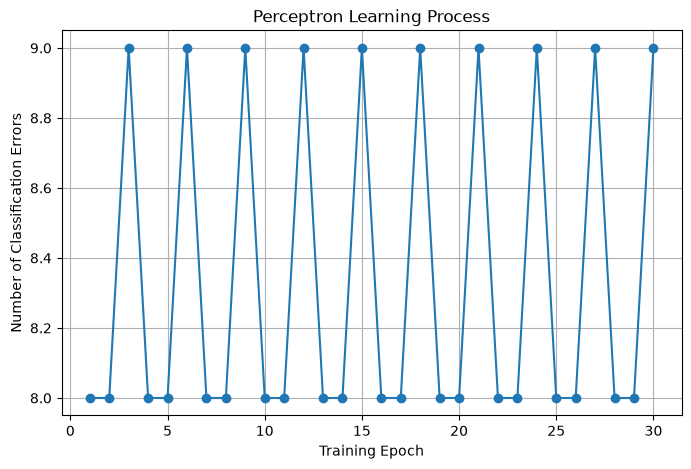

In [6]:
import matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron

errors = []

for epoch in range(1, 31):
    temp_model = Perceptron(
        max_iter=epoch,
        tol=None,
        random_state=42,
        shuffle=False
    )
    temp_model.fit(X_train, y_train)
    predictions = temp_model.predict(X_train)
    errors.append((predictions != y_train).sum())

plt.figure(figsize=(8, 5))
plt.plot(range(1, 31), errors, marker="o")
plt.xlabel("Training Epoch")
plt.ylabel("Number of Classification Errors")
plt.title("Perceptron Learning Process")
plt.grid(True)
plt.show()